# 01 eda

Análise exploratória (EDA) sobre o dataset completo.

Saídas em reports/: tabelas CSV + eda_summary.txt + figures/*.png

In [1]:
# Configuração (caminhos e constantes do projeto)
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW_CSV = ROOT / "data set.csv"
DATA_DIR = ROOT / "data"
REPORTS_DIR = ROOT / "reports"
FIG_DIR = REPORTS_DIR / "figures"
RAW_PARQUET = DATA_DIR / "raw.parquet"

SEED = 42
TARGET = "CLASSI_FIN"
DATE_COLS = ["DT_NOTIFIC", "DT_SIN_PRI", "DT_NASC", "DT_INVEST", "DT_ENCERRA"]

In [2]:
import numpy as np
import pandas as pd
import matplotlib
%matplotlib inline
import matplotlib.pyplot as plt
import seaborn as sns

REPORTS_DIR.mkdir(exist_ok=True); FIG_DIR.mkdir(exist_ok=True)
sns.set_theme(style="whitegrid")
df = pd.read_parquet(RAW_PARQUET)
out = open(REPORTS_DIR / "eda_summary.txt", "w")
def log(*a):
    print(*a); print(*a, file=out)

log(f"Shape: {df.shape}")

Shape: (6732548, 56)


## Alvo

In [3]:
log("\n== Alvo ==")
vc = df[TARGET].value_counts(); log(pd.concat([vc, (vc/len(df)).round(4)], axis=1))


== Alvo ==
                          count   count
CLASSI_FIN                             
Dengue                  4307513  0.6398
Discarded/Inconclusive  2100029  0.3119
Chikungunya              325000  0.0483
CLASSI_FIN                    6  0.0000


## Atributos constantes

In [4]:
log("\n== Atributos constantes ==")
const = [c for c in df.columns if df[c].nunique(dropna=False) == 1]; log(const)


== Atributos constantes ==


[]


## Valores nulos (NaN) por coluna

In [5]:
log("\n== Valores nulos (NaN) por coluna ==")
na = df.isna().sum(); log(na[na > 0])


== Valores nulos (NaN) por coluna ==


DT_NOTIFIC         6
SEM_NOT            6
NU_ANO             6
SG_UF_NOT          6
ID_MUNICIP         8
ID_REGIONA         6
ID_UNIDADE         6
DT_SIN_PRI         9
SEM_PRI           57
DT_NASC       389576
NU_IDADE_N         6
CS_SEXO            6
CS_GESTANT         6
CS_RACA            6
CS_ESCOL_N         6
SG_UF              6
ID_MN_RESI         6
ID_RG_RESI         6
ID_PAIS            6
DT_INVEST       1634
FEBRE              6
MIALGIA            6
CEFALEIA           6
EXANTEMA           6
VOMITO             6
NAUSEA             6
DOR_COSTAS         6
CONJUNTVIT         6
ARTRITE            6
ARTRALGIA          6
PETEQUIA_N         6
LEUCOPENIA         6
LACO               6
DOR_RETRO          6
DIABETES           6
HEMATOLOG          6
HEPATOPAT          6
RENAL              6
HIPERTENSA         6
ACIDO_PEPT         6
AUTO_IMUNE         6
RESUL_SORO         6
RESUL_NS1          6
RESUL_VI_N         6
RESUL_PCR_         6
HISTOPA_N          6
IMUNOH_N           6
HOSPITALIZ   

## Datas inválidas / fora de faixa

In [6]:
log("\n== Datas inválidas / fora de faixa ==")
for c in DATE_COLS:
    log(c, "min", df[c].min(), "max", df[c].max(), "NaT", int(df[c].isna().sum()))


== Datas inválidas / fora de faixa ==
DT_NOTIFIC min 2012-12-30 00:00:00 max 2021-01-02 00:00:00 NaT 6
DT_SIN_PRI min 0201-01-05 00:00:00 max 2106-05-09 00:00:00 NaT 9
DT_NASC min 1900-01-01 00:00:00 max 2020-12-28 00:00:00 NaT 389576
DT_INVEST min 1916-02-26 00:00:00 max 2021-01-13 00:00:00 NaT 1634
DT_ENCERRA min 0216-09-22 00:00:00 max 2021-02-18 00:00:00 NaT 596


## Duplicatas exatas

In [7]:
log("\n== Duplicatas exatas ==")
log(int(df.duplicated().sum()))


== Duplicatas exatas ==


8751


## Registros por ano

In [8]:
log("\n== Registros por ano ==")
yr = pd.crosstab(df["NU_ANO"], df[TARGET]); log(yr)
yr.to_csv(REPORTS_DIR / "classe_por_ano.csv")


== Registros por ano ==


CLASSI_FIN  Chikungunya  Dengue  Discarded/Inconclusive
NU_ANO                                                 
2012.0                0     282                      96
2013.0                0  738776                  253471
2014.0                0  269400                  160887
2015.0              363  861341                  352197
2016.0            69222  850956                  442515
2017.0           113087  120753                  165829
2018.0            50271  131691                  114509
2019.0            69958  878249                  366398
2020.0            22097  456043                  244090
2021.0                2      22                      37


## Idade (NU_IDADE_N)

In [9]:
log("\n== Idade (NU_IDADE_N) ==")
log(df["NU_IDADE_N"].describe())
log("idade<0:", int((df.NU_IDADE_N < 0).sum()), " idade>110:", int((df.NU_IDADE_N > 110).sum()))
d = (df.DT_NOTIFIC.dt.year - df.DT_NASC.dt.year)
log("|idade calculada - NU_IDADE_N|>2:", int(((d - df.NU_IDADE_N).abs() > 2).sum()))


== Idade (NU_IDADE_N) ==
count    6.732542e+06
mean     3.241043e+01
std      1.840322e+01
min      0.000000e+00
25%      1.900000e+01
50%      3.000000e+01
75%      4.500000e+01
max      9.990000e+02
Name: NU_IDADE_N, dtype: float64
idade<0: 0  idade>110: 8


|idade calculada - NU_IDADE_N|>2: 286933


## Intervalos entre datas (dias)

In [10]:
log("\n== Intervalos entre datas (dias) ==")
for a, b in [("DT_SIN_PRI", "DT_NOTIFIC"), ("DT_NOTIFIC", "DT_INVEST"), ("DT_NOTIFIC", "DT_ENCERRA")]:
    dd = (df[b] - df[a]).dt.days; log(f"{b}-{a}:", dd.describe()[["min", "50%", "max"]].to_dict(), "negativos:", int((dd < 0).sum()))

# Colunas categóricas/binárias: distribuição de códigos (inclui 'ignorado')
cat_cols = [c for c in df.columns if c not in DATE_COLS + [TARGET] and df[c].dtype == "float32"
            and df[c].nunique() <= 12]


== Intervalos entre datas (dias) ==


DT_NOTIFIC-DT_SIN_PRI: {'min': -32871.0, '50%': 2.0, 'max': 664132.0} negativos: 270
DT_INVEST-DT_NOTIFIC: {'min': -36525.0, '50%': 0.0, 'max': 1096.0} negativos: 1169


DT_ENCERRA-DT_NOTIFIC: {'min': -657224.0, '50%': 36.0, 'max': 1096.0} negativos: 163


## Distribuição de códigos (colunas com <=12 valores)

In [11]:
log("\n== Distribuição de códigos (colunas com <=12 valores) ==")
rows = []
for c in cat_cols:
    p = df[c].value_counts(normalize=True, dropna=False).round(4).to_dict()
    log(c, p); rows.append({"col": c, **{str(k): v for k, v in p.items()}})
pd.DataFrame(rows).to_csv(REPORTS_DIR / "codigos_por_coluna.csv", index=False)


== Distribuição de códigos (colunas com <=12 valores) ==
NU_ANO {2016.0: 0.2024, 2019.0: 0.1953, 2015.0: 0.1803, 2013.0: 0.1474, 2020.0: 0.1073, 2014.0: 0.0639, 2017.0: 0.0594, 2018.0: 0.044, 2012.0: 0.0001, 2021.0: 0.0, nan: 0.0}
CS_SEXO {0.0: 0.5542, 1.0: 0.4443, 2.0: 0.0014, 9.0: 0.0, nan: 0.0}
CS_GESTANT {6.0: 0.6171, 5.0: 0.2679, 9.0: 0.1071, 2.0: 0.0026, 3.0: 0.0021, 1.0: 0.002, 4.0: 0.0012, nan: 0.0}
CS_RACA {9.0: 0.3427, 4.0: 0.3382, 1.0: 0.2734, 2.0: 0.0362, 3.0: 0.0072, 5.0: 0.0023, nan: 0.0}
CS_ESCOL_N {9.0: 0.5751, 6.0: 0.1114, 10.0: 0.0698, 3.0: 0.0595, 5.0: 0.051, 4.0: 0.0343, 1.0: 0.0335, 8.0: 0.0245, 2.0: 0.0203, 7.0: 0.015, 0.0: 0.0056, nan: 0.0}
FEBRE {9.0: 0.5241, 1.0: 0.3725, 2.0: 0.1034, nan: 0.0}
MIALGIA {9.0: 0.5241, 1.0: 0.3401, 2.0: 0.1358, nan: 0.0}
CEFALEIA {9.0: 0.5241, 1.0: 0.3454, 2.0: 0.1305, nan: 0.0}
EXANTEMA {9.0: 0.5241, 2.0: 0.3836, 1.0: 0.0922, nan: 0.0}
VOMITO {9.0: 0.5241, 2.0: 0.3819, 1.0: 0.094, nan: 0.0}
NAUSEA {9.0: 0.5241, 2.0: 0.3335, 1.0: 

ARTRITE {9.0: 0.5241, 2.0: 0.4331, 1.0: 0.0428, nan: 0.0}
ARTRALGIA {9.0: 0.5241, 2.0: 0.3815, 1.0: 0.0944, nan: 0.0}
PETEQUIA_N {9.0: 0.5241, 2.0: 0.4393, 1.0: 0.0366, nan: 0.0}
LEUCOPENIA {9.0: 0.5241, 2.0: 0.4557, 1.0: 0.0202, nan: 0.0}
LACO {9.0: 0.5241, 2.0: 0.4581, 1.0: 0.0178, nan: 0.0}
DOR_RETRO {9.0: 0.5241, 2.0: 0.333, 1.0: 0.1429, nan: 0.0}
DIABETES {9.0: 0.5241, 2.0: 0.4664, 1.0: 0.0095, nan: 0.0}
HEMATOLOG {9.0: 0.5241, 2.0: 0.474, 1.0: 0.0019, nan: 0.0}
HEPATOPAT {9.0: 0.5241, 2.0: 0.4739, 1.0: 0.002, nan: 0.0}
RENAL {9.0: 0.5241, 2.0: 0.4742, 1.0: 0.0017, nan: 0.0}
HIPERTENSA {9.0: 0.5241, 2.0: 0.4526, 1.0: 0.0233, nan: 0.0}
ACIDO_PEPT {9.0: 0.5241, 2.0: 0.4737, 1.0: 0.0022, nan: 0.0}
AUTO_IMUNE {9.0: 0.5241, 2.0: 0.4742, 1.0: 0.0017, nan: 0.0}
RESUL_SORO {4.0: 0.9864, 2.0: 0.0073, 1.0: 0.0043, 3.0: 0.002, nan: 0.0}
RESUL_NS1 {4.0: 0.976, 2.0: 0.0204, 1.0: 0.0032, 3.0: 0.0004, nan: 0.0}
RESUL_VI_N {4.0: 0.9994, 2.0: 0.0004, 3.0: 0.0001, 1.0: 0.0, nan: 0.0}
RESUL_PCR_ {4.

IMUNOH_N {4.0: 0.9993, 3.0: 0.0003, 2.0: 0.0003, 1.0: 0.0001, nan: 0.0}
HOSPITALIZ {2.0: 0.545, 9.0: 0.4352, 1.0: 0.0197, nan: 0.0}
TPAUTOCTO {1.0: 0.51, 9.0: 0.4416, 3.0: 0.0348, 2.0: 0.0135, nan: 0.0}
EVOLUCAO {1.0: 0.9067, 9.0: 0.0928, 3.0: 0.0003, 2.0: 0.0001, 4.0: 0.0, nan: 0.0}


## Cardinalidade das colunas geográficas

In [12]:
log("\n== Cardinalidade das colunas geográficas ==")
geo = ["SG_UF_NOT", "ID_MUNICIP", "ID_REGIONA", "ID_UNIDADE", "SG_UF", "ID_MN_RESI", "ID_RG_RESI", "COUFINF", "COMUNINF"]
log({c: int(df[c].nunique()) for c in geo})


== Cardinalidade das colunas geográficas ==
{'SG_UF_NOT': 27, 'ID_MUNICIP': 4667, 'ID_REGIONA': 342, 'ID_UNIDADE': 39231, 'SG_UF': 28, 'ID_MN_RESI': 4886, 'ID_RG_RESI': 344, 'COUFINF': 28, 'COMUNINF': 4399}


## Taxa de 'ignorado' (9) nos sintomas/comorbidades por classe

In [13]:
log("\n== Taxa de 'ignorado' (9) nos sintomas/comorbidades por classe ==")
sint = ["FEBRE","MIALGIA","CEFALEIA","EXANTEMA","VOMITO","NAUSEA","DOR_COSTAS","CONJUNTVIT","ARTRITE","ARTRALGIA",
        "PETEQUIA_N","LEUCOPENIA","LACO","DOR_RETRO","DIABETES","HEMATOLOG","HEPATOPAT","RENAL","HIPERTENSA","ACIDO_PEPT","AUTO_IMUNE"]
log(df[sint].eq(9).groupby(df[TARGET], observed=True).mean().round(3).T)
log("\nValores de FEBRE:", df.FEBRE.value_counts().to_dict())


== Taxa de 'ignorado' (9) nos sintomas/comorbidades por classe ==


CLASSI_FIN  CLASSI_FIN  Chikungunya  Dengue  Discarded/Inconclusive
FEBRE              0.0          1.0   0.511                   0.478
MIALGIA            0.0          1.0   0.511                   0.478
CEFALEIA           0.0          1.0   0.511                   0.478
EXANTEMA           0.0          1.0   0.511                   0.478
VOMITO             0.0          1.0   0.511                   0.478
NAUSEA             0.0          1.0   0.511                   0.478
DOR_COSTAS         0.0          1.0   0.511                   0.478
CONJUNTVIT         0.0          1.0   0.511                   0.478
ARTRITE            0.0          1.0   0.511                   0.478
ARTRALGIA          0.0          1.0   0.511                   0.478
PETEQUIA_N         0.0          1.0   0.511                   0.478
LEUCOPENIA         0.0          1.0   0.511                   0.478
LACO               0.0          1.0   0.511                   0.478
DOR_RETRO          0.0          1.0   0.511     

## Resultados laboratoriais (4 = não realizado?) por classe

In [14]:
log("\n== Resultados laboratoriais (4 = não realizado?) por classe ==")
lab = ["RESUL_SORO","RESUL_NS1","RESUL_VI_N","RESUL_PCR_","HISTOPA_N","IMUNOH_N"]
for c in lab:
    log(c); log(pd.crosstab(df[c], df[TARGET], normalize="columns").round(3))


== Resultados laboratoriais (4 = não realizado?) por classe ==
RESUL_SORO


CLASSI_FIN  Chikungunya  Dengue  Discarded/Inconclusive
RESUL_SORO                                             
1.0                 0.0   0.006                   0.001
2.0                 0.0   0.005                   0.014
3.0                 0.0   0.002                   0.003
4.0                 1.0   0.988                   0.982
RESUL_NS1


CLASSI_FIN  Chikungunya  Dengue  Discarded/Inconclusive
RESUL_NS1                                              
1.0                 0.0   0.005                   0.001
2.0                 0.0   0.012                   0.041
3.0                 0.0   0.000                   0.000
4.0                 1.0   0.983                   0.958
RESUL_VI_N


CLASSI_FIN  Chikungunya  Dengue  Discarded/Inconclusive
RESUL_VI_N                                             
1.0                 0.0   0.000                   0.000
2.0                 0.0   0.000                   0.000
3.0                 0.0   0.000                   0.000
4.0                 1.0   0.999                   0.999
RESUL_PCR_


CLASSI_FIN  Chikungunya  Dengue  Discarded/Inconclusive
RESUL_PCR_                                             
1.0                 0.0   0.000                   0.000
2.0                 0.0   0.001                   0.001
3.0                 0.0   0.000                   0.000
4.0                 1.0   0.999                   0.999
HISTOPA_N


CLASSI_FIN  Chikungunya  Dengue  Discarded/Inconclusive
HISTOPA_N                                              
1.0                 0.0     0.0                   0.000
2.0                 0.0     0.0                   0.000
3.0                 0.0     0.0                   0.000
4.0                 1.0     1.0                   0.999
IMUNOH_N


CLASSI_FIN  Chikungunya  Dengue  Discarded/Inconclusive
IMUNOH_N                                               
1.0                 0.0   0.000                   0.000
2.0                 0.0   0.000                   0.000
3.0                 0.0   0.000                   0.000
4.0                 1.0   0.999                   0.999


## Prevalência de sintomas (==1) por classe

In [15]:
log("\n== Prevalência de sintomas (==1) por classe ==")
prev = df[sint].eq(1).groupby(df[TARGET], observed=True).mean().round(3).T; log(prev)
prev.to_csv(REPORTS_DIR / "sintomas_por_classe.csv")


== Prevalência de sintomas (==1) por classe ==


CLASSI_FIN  CLASSI_FIN  Chikungunya  Dengue  Discarded/Inconclusive
FEBRE              0.0          0.0   0.398                   0.378
MIALGIA            0.0          0.0   0.370                   0.330
CEFALEIA           0.0          0.0   0.374                   0.340
EXANTEMA           0.0          0.0   0.108                   0.073
VOMITO             0.0          0.0   0.102                   0.093
NAUSEA             0.0          0.0   0.160                   0.127
DOR_COSTAS         0.0          0.0   0.127                   0.099
CONJUNTVIT         0.0          0.0   0.015                   0.012
ARTRITE            0.0          0.0   0.050                   0.035
ARTRALGIA          0.0          0.0   0.105                   0.088
PETEQUIA_N         0.0          0.0   0.043                   0.028
LEUCOPENIA         0.0          0.0   0.025                   0.013
LACO               0.0          0.0   0.023                   0.011
DOR_RETRO          0.0          0.0   0.170     

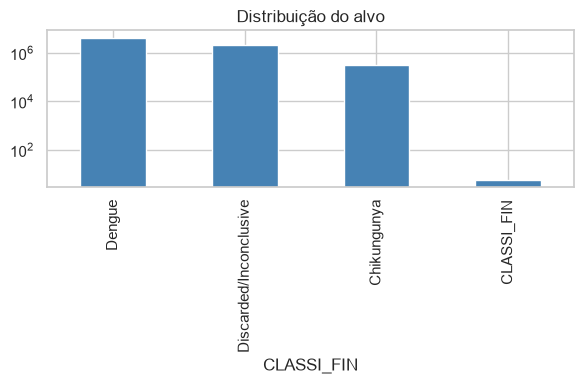

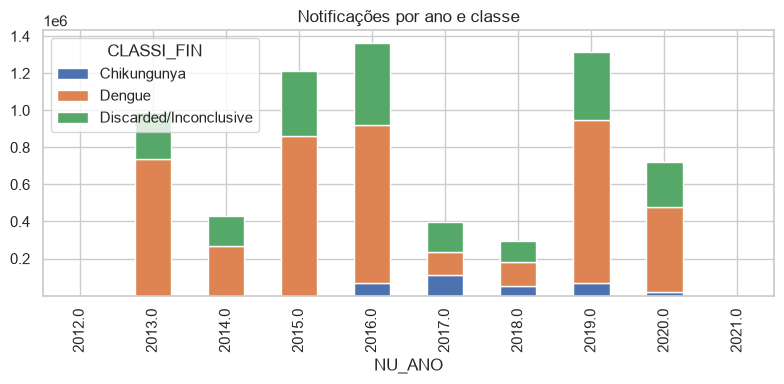

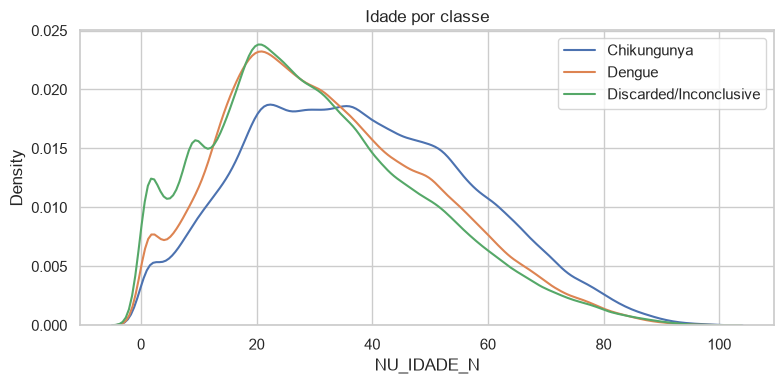

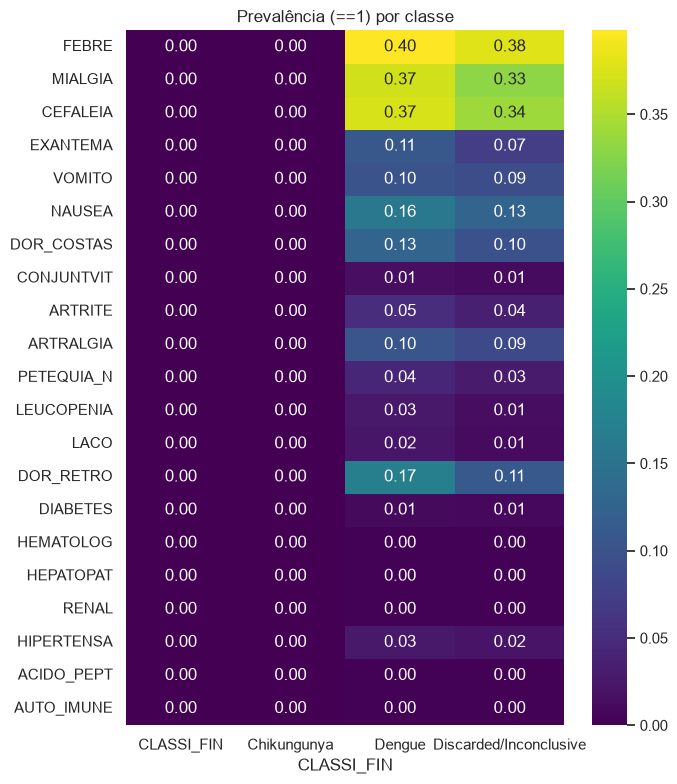

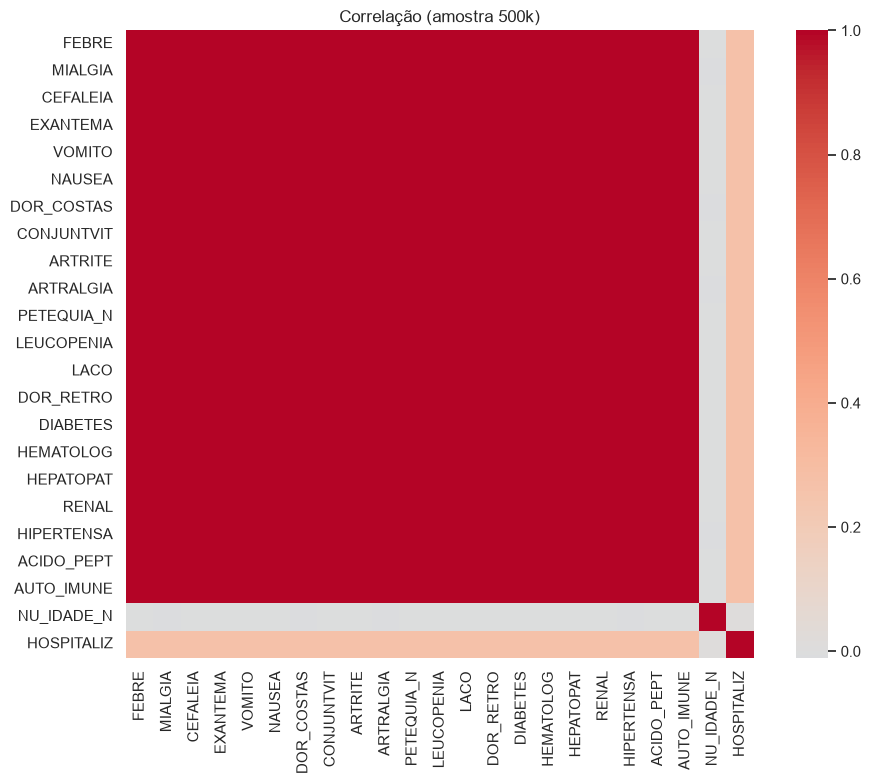

In [16]:
# Figuras
fig, ax = plt.subplots(figsize=(6, 4)); vc.plot.bar(ax=ax, color="steelblue"); ax.set_title("Distribuição do alvo"); ax.set_yscale("log")
fig.tight_layout(); fig.savefig(FIG_DIR / "alvo.png", dpi=120); plt.show()

fig, ax = plt.subplots(figsize=(8, 4)); yr.plot.bar(stacked=True, ax=ax); ax.set_title("Notificações por ano e classe")
fig.tight_layout(); fig.savefig(FIG_DIR / "classe_por_ano.png", dpi=120); plt.show()

fig, ax = plt.subplots(figsize=(8, 4))
for k, g in df[df.NU_IDADE_N.between(0, 110)].groupby(TARGET, observed=True):
    sns.kdeplot(g.NU_IDADE_N.sample(min(len(g), 200_000), random_state=0), ax=ax, label=k, common_norm=False)
ax.legend(); ax.set_title("Idade por classe"); fig.tight_layout(); fig.savefig(FIG_DIR / "idade.png", dpi=120); plt.show()

fig, ax = plt.subplots(figsize=(7, 8)); sns.heatmap(prev, annot=True, fmt=".2f", cmap="viridis", ax=ax)
ax.set_title("Prevalência (==1) por classe"); fig.tight_layout(); fig.savefig(FIG_DIR / "sintomas_heatmap.png", dpi=120); plt.show()

num = df[sint + ["NU_IDADE_N", "HOSPITALIZ"]].sample(500_000, random_state=0)
fig, ax = plt.subplots(figsize=(10, 8)); sns.heatmap(num.corr(), cmap="coolwarm", center=0, ax=ax, square=True)
ax.set_title("Correlação (amostra 500k)"); fig.tight_layout(); fig.savefig(FIG_DIR / "correlacao.png", dpi=120); plt.show()
out.close()